<a href="https://colab.research.google.com/github/akisha-dev/DEEP-LEARNING-IBM-PROJECT/blob/main/DCGAN_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# DCGAN PROJECT
# Image Generation Using Deep Convolutional GAN
# Dataset: MNIST
# ============================================================

print("=" * 60)
print("DCGAN - MNIST IMAGE GENERATION PROJECT")
print("=" * 60)
print("Project: Image Generation Using Deep Convolutional GAN")
print("Dataset: MNIST")
print("=" * 60)

DCGAN - MNIST IMAGE GENERATION PROJECT
Project: Image Generation Using Deep Convolutional GAN
Dataset: MNIST


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available.")
    print("Go to Runtime -> Change runtime type -> GPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
from torchvision.utils import make_grid

from torch.utils.data import DataLoader

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# Random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Using device: cuda
Random seed: 42


In [ ]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

LATENT_DIM = 100
IMAGE_SIZE = 28
CHANNELS = 1

BATCH_SIZE = 128

BASELINE_LR = 0.0002

NUM_EPOCHS = 20

# Epochs at which images will be saved
CHECKPOINT_EPOCHS = [1, 5, 10, 15, 20]

print("Latent dimension:", LATENT_DIM)
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", BASELINE_LR)
print("Epochs:", NUM_EPOCHS)

Latent dimension: 100
Image size: 28 x 28
Batch size: 128
Learning rate: 0.0002
Epochs: 20


In [ ]:
# ============================================================
# CREATE PROJECT FOLDERS
# ============================================================

os.makedirs("results", exist_ok=True)

os.makedirs(
    "results/baseline",
    exist_ok=True
)

os.makedirs(
    "results/label_smoothing",
    exist_ok=True
)

os.makedirs(
    "results/lr_0001",
    exist_ok=True
)

os.makedirs(
    "results/lr_0003",
    exist_ok=True
)

os.makedirs(
    "models",
    exist_ok=True
)

print("Project folders created.")

Project folders created.


In [ ]:
# ============================================================
# MNIST PREPROCESSING
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        (0.5,),
        (0.5,)
    )
])

print("MNIST transformation pipeline created.")

MNIST transformation pipeline created.


In [ ]:
# ============================================================
# LOAD MNIST DATASET
# ============================================================

dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

print("Dataset loaded successfully.")
print("Number of training images:", len(dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 43.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.28MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 11.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.1MB/s]

Dataset loaded successfully.
Number of training images: 60000


In [ ]:
# ============================================================
# DATALOADER
# ============================================================

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("DataLoader created.")
print("Number of batches:", len(dataloader))

DataLoader created.
Number of batches: 469


Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])


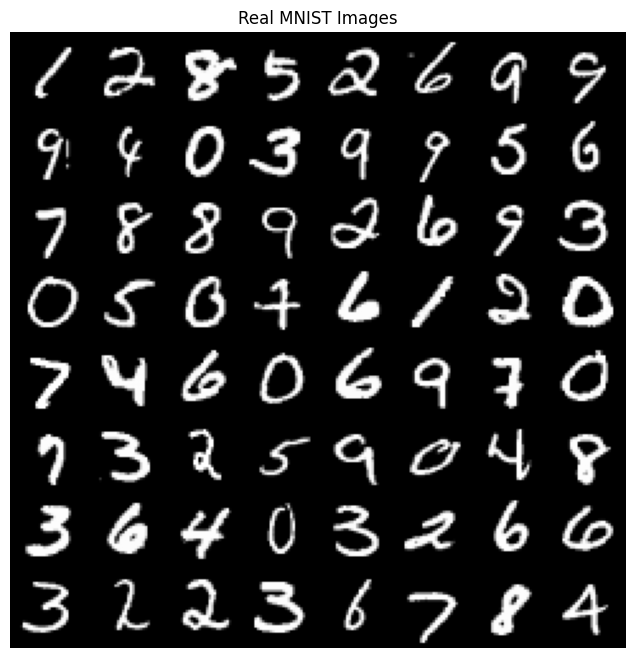

In [ ]:
# ============================================================
# DISPLAY REAL MNIST IMAGES
# ============================================================

real_images, labels = next(iter(dataloader))

print("Image batch shape:", real_images.shape)
print("Label batch shape:", labels.shape)

plt.figure(figsize=(8, 8))

grid = make_grid(
    real_images[:64],
    nrow=8,
    normalize=True
)

plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray"
)

plt.axis("off")
plt.title("Real MNIST Images")

plt.show()

In [ ]:
# ============================================================
# GENERATOR
# ============================================================

class Generator(nn.Module):

    def __init__(self, latent_dim=100):

        super().__init__()

        self.model = nn.Sequential(

            # Input:
            # 100 x 1 x 1

            nn.ConvTranspose2d(
                latent_dim,
                128,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),

            # 128 x 7 x 7

            nn.BatchNorm2d(128),

            nn.ReLU(True),


            # 128 x 7 x 7
            # -> 64 x 14 x 14

            nn.ConvTranspose2d(
                128,
                64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(True),


            # 64 x 14 x 14
            # -> 1 x 28 x 28

            nn.ConvTranspose2d(
                64,
                1,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),

            # Output range [-1, 1]

            nn.Tanh()
        )


    def forward(self, x):

        return self.model(x)


print("Generator class created.")

Generator class created.


In [ ]:
# ============================================================
# CREATE GENERATOR
# ============================================================

G = Generator(
    latent_dim=LATENT_DIM
).to(device)

print(G)

Generator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)


In [ ]:
# ============================================================
# GENERATOR STANDALONE TEST
# ============================================================

test_noise = torch.randn(
    16,
    100,
    1,
    1,
    device=device
)

test_generated = G(test_noise)

print("Generator input shape:",
      test_noise.shape)

print("Generator output shape:",
      test_generated.shape)


assert test_generated.shape == (
    16,
    1,
    28,
    28
), "Generator output shape is incorrect!"

print("\nGenerator test PASSED.")

Generator input shape: torch.Size([16, 100, 1, 1])
Generator output shape: torch.Size([16, 1, 28, 28])

Generator test PASSED.


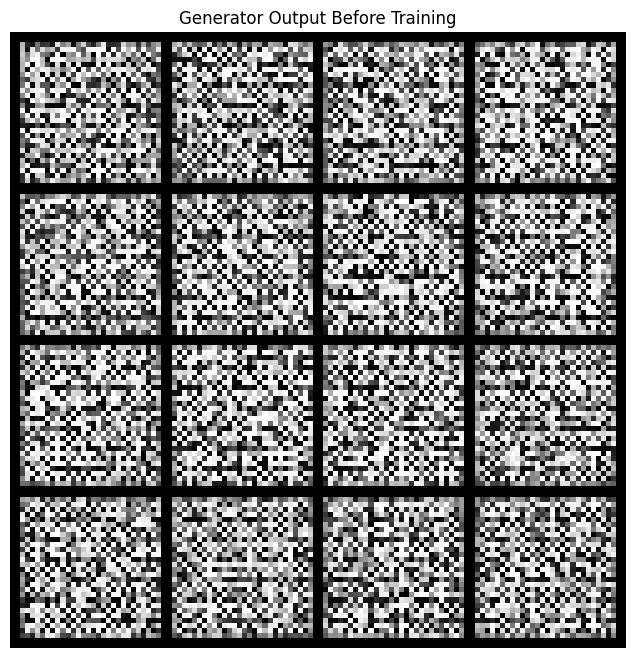

In [ ]:
# ============================================================
# GENERATOR BEFORE TRAINING
# ============================================================

plt.figure(figsize=(8, 8))

grid = make_grid(
    test_generated.detach().cpu(),
    nrow=4,
    normalize=True
)

plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray"
)

plt.axis("off")
plt.title("Generator Output Before Training")

plt.show()

In [ ]:
# ============================================================
# DISCRIMINATOR
# ============================================================

class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = nn.Sequential(

            # Input:
            # 1 x 28 x 28
            #
            # Output:
            # 64 x 14 x 14

            nn.Conv2d(
                1,
                64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.LeakyReLU(
                0.2,
                inplace=True
            ),


            # 64 x 14 x 14
            #
            # Output:
            # 128 x 7 x 7

            nn.Conv2d(
                64,
                128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(128),

            nn.LeakyReLU(
                0.2,
                inplace=True
            ),


            nn.Flatten(),


            # 128 x 7 x 7
            #
            # Output:
            # 1

            nn.Linear(
                128 * 7 * 7,
                1
            )
        )


    def forward(self, x):

        return self.model(x)


print("Discriminator class created.")

Discriminator class created.


In [ ]:
# ============================================================
# CREATE DISCRIMINATOR
# ============================================================

D = Discriminator().to(device)

print(D)

Discriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Linear(in_features=6272, out_features=1, bias=True)
  )
)


In [ ]:
# ============================================================
# DISCRIMINATOR STANDALONE TEST
# ============================================================

test_images = torch.randn(
    16,
    1,
    28,
    28,
    device=device
)

test_disc_output = D(test_images)

print(
    "Discriminator input shape:",
    test_images.shape
)

print(
    "Discriminator output shape:",
    test_disc_output.shape
)


assert test_disc_output.shape == (
    16,
    1
), "Discriminator output shape is incorrect!"

print("\nDiscriminator test PASSED.")

Discriminator input shape: torch.Size([16, 1, 28, 28])
Discriminator output shape: torch.Size([16, 1])

Discriminator test PASSED.


In [ ]:
# ============================================================
# LOSS FUNCTION
# ============================================================

criterion = nn.BCEWithLogitsLoss()

print("Loss function:", criterion)

Loss function: BCEWithLogitsLoss()


In [ ]:
# ============================================================
# FIXED NOISE FOR CHECKPOINT COMPARISON
# ============================================================

fixed_noise = torch.randn(
    64,
    LATENT_DIM,
    1,
    1,
    device=device
)

print(
    "Fixed noise shape:",
    fixed_noise.shape
)

Fixed noise shape: torch.Size([64, 100, 1, 1])


In [ ]:
# ============================================================
# FUNCTION TO SAVE GENERATED IMAGE GRIDS
# ============================================================

def save_generated_images(
    generator,
    noise,
    epoch,
    folder,
    title_prefix="Generated Images"
):

    generator.eval()

    with torch.no_grad():

        generated_images = generator(noise)

    generator.train()

    grid = make_grid(
        generated_images.cpu(),
        nrow=8,
        normalize=True
    )

    plt.figure(figsize=(8, 8))

    plt.imshow(
        grid.permute(1, 2, 0),
        cmap="gray"
    )

    plt.axis("off")

    plt.title(
        f"{title_prefix} - Epoch {epoch}"
    )

    filename = os.path.join(
        folder,
        f"epoch_{epoch:03d}.png"
    )

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


Testing image-saving function...


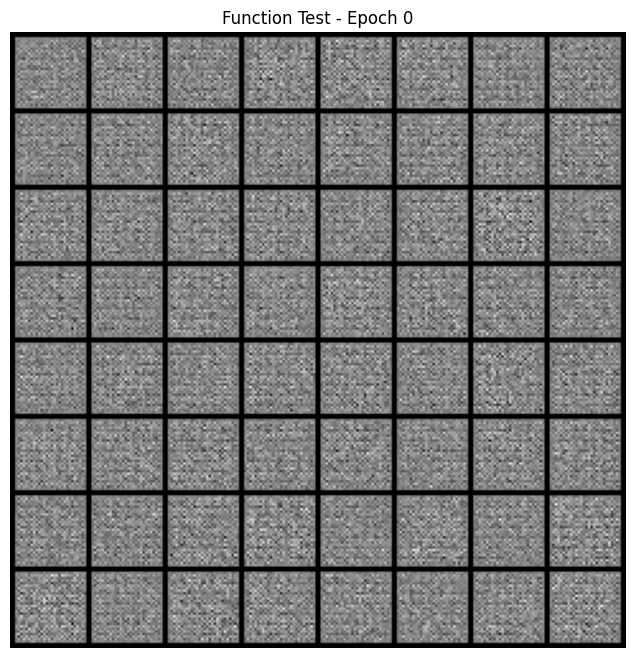

Cell 20 function test completed.


In [ ]:
# TEST CELL 20

print("Testing image-saving function...")

save_generated_images(
    G,
    fixed_noise,
    epoch=0,
    folder="results/baseline",
    title_prefix="Function Test"
)

print("Cell 20 function test completed.")

The Minimax Training ObjectiveGenerative Adversarial Networks are trained using a two-player minimax game. The value function is defined as:$$\min_G \max_D V(D, G) = \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

The Discriminator ($D$) seeks to maximize this objective. It wants to output a value close to 1 for real images $x$ (maximizing $\log D(x)$) and a value close to 0 for generated images $G(z)$ (maximizing $\log(1 - D(G(z)))$).

The Generator ($G$) seeks to minimize this objective. It is trained to fool the Discriminator into outputting a 1 for its generated images, thereby minimizing $\log(1 - D(G(z)))

.Implementation Note: In our code, to prevent vanishing gradients early in training when the Discriminator is much stronger, the Generator is instead trained with the non-saturating heuristic to maximize $\log D(G(z))$.

In [ ]:
# ============================================================
# GENERAL GAN TRAINING FUNCTION
# ============================================================

def train_dcgan(
    generator,
    discriminator,
    dataloader,
    optimizer_G,
    optimizer_D,
    epochs,
    fixed_noise,
    result_folder,
    experiment_name="Experiment",
    label_smoothing=False
):

    generator.train()
    discriminator.train()

    g_losses = []
    d_losses = []

    epoch_g_losses = []
    epoch_d_losses = []


    print("=" * 60)
    print("STARTING:", experiment_name)
    print("=" * 60)


    for epoch in range(1, epochs + 1):

        running_g_loss = 0.0
        running_d_loss = 0.0


        for real_images, _ in dataloader:

            real_images = real_images.to(device)

            current_batch_size = real_images.size(0)


            # =================================================
            # TRAIN DISCRIMINATOR
            # =================================================

            discriminator.zero_grad()


            # -------------------------
            # REAL IMAGES
            # -------------------------

            real_output = discriminator(
                real_images
            )

            if label_smoothing:

                real_labels = torch.full_like(
                    real_output,
                    0.9
                )

            else:

                real_labels = torch.ones_like(
                    real_output
                )


            real_loss = criterion(
                real_output,
                real_labels
            )


            # -------------------------
            # FAKE IMAGES
            # -------------------------

            noise = torch.randn(
                current_batch_size,
                LATENT_DIM,
                1,
                1,
                device=device
            )

            fake_images = generator(noise)


            fake_output = discriminator(
                fake_images.detach()
            )

            fake_labels = torch.zeros_like(
                fake_output
            )


            fake_loss = criterion(
                fake_output,
                fake_labels
            )


            # Total D loss

            d_loss = (
                real_loss +
                fake_loss
            )


            d_loss.backward()

            optimizer_D.step()


            # =================================================
            # TRAIN GENERATOR
            # =================================================

            generator.zero_grad()


            fake_output = discriminator(
                fake_images
            )


            generator_labels = torch.ones_like(
                fake_output
            )


            g_loss = criterion(
                fake_output,
                generator_labels
            )


            g_loss.backward()

            optimizer_G.step()


            # =================================================
            # STORE LOSSES
            # =================================================

            g_losses.append(
                g_loss.item()
            )

            d_losses.append(
                d_loss.item()
            )

            running_g_loss += g_loss.item()
            running_d_loss += d_loss.item()


        # =====================================================
        # AVERAGE EPOCH LOSSES
        # =====================================================

        avg_g_loss = (
            running_g_loss /
            len(dataloader)
        )

        avg_d_loss = (
            running_d_loss /
            len(dataloader)
        )


        epoch_g_losses.append(
            avg_g_loss
        )

        epoch_d_losses.append(
            avg_d_loss
        )


        print(
            f"Epoch [{epoch:02d}/{epochs}] | "
            f"D Loss: {avg_d_loss:.4f} | "
            f"G Loss: {avg_g_loss:.4f}"
        )


        # =====================================================
        # SAVE CHECKPOINT IMAGES
        # =====================================================

        if epoch in CHECKPOINT_EPOCHS:

            save_generated_images(
                generator,
                fixed_noise,
                epoch,
                result_folder,
                experiment_name
            )


    print("=" * 60)
    print("TRAINING COMPLETE:", experiment_name)
    print("=" * 60)


    return {
        "g_losses": g_losses,
        "d_losses": d_losses,
        "epoch_g_losses": epoch_g_losses,
        "epoch_d_losses": epoch_d_losses
    }

In [ ]:
# ============================================================
# BASELINE MODELS
# ============================================================

G_baseline = Generator(
    LATENT_DIM
).to(device)

D_baseline = Discriminator().to(device)


optimizer_G_baseline = optim.Adam(
    G_baseline.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D_baseline = optim.Adam(
    D_baseline.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Baseline models and optimizers created.")

Baseline models and optimizers created.


STARTING: Baseline
Epoch [01/20] | D Loss: 0.6156 | G Loss: 2.1054


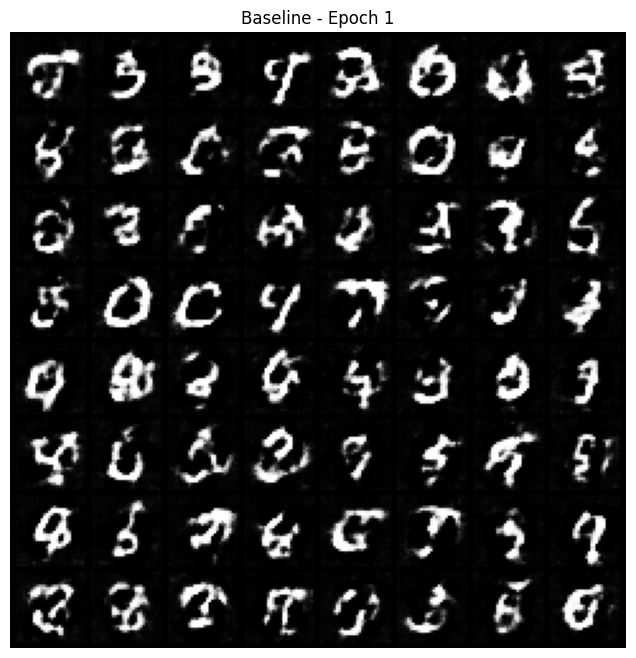

Epoch [02/20] | D Loss: 0.6206 | G Loss: 1.6893
Epoch [03/20] | D Loss: 0.5991 | G Loss: 1.7780
Epoch [04/20] | D Loss: 0.6243 | G Loss: 1.7736
Epoch [05/20] | D Loss: 0.6397 | G Loss: 1.7662


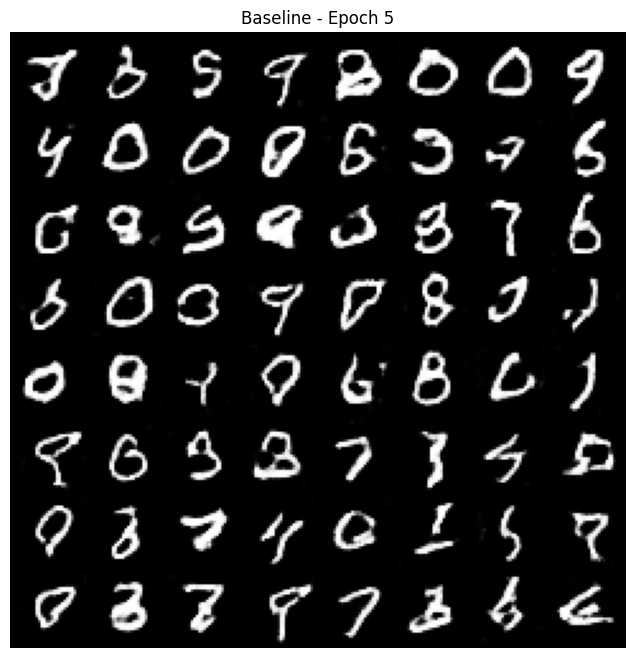

Epoch [06/20] | D Loss: 0.6459 | G Loss: 1.7826
Epoch [07/20] | D Loss: 0.6788 | G Loss: 1.7641
Epoch [08/20] | D Loss: 0.6843 | G Loss: 1.7764
Epoch [09/20] | D Loss: 0.6706 | G Loss: 1.8121
Epoch [10/20] | D Loss: 0.6672 | G Loss: 1.8447


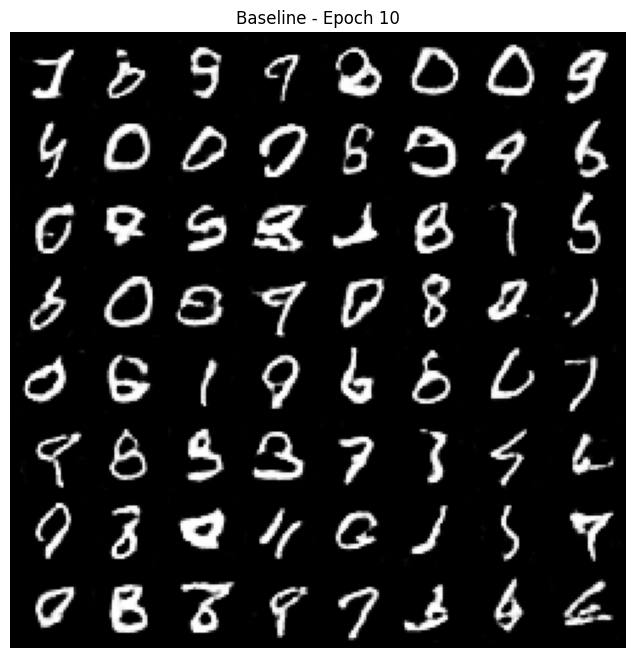

Epoch [11/20] | D Loss: 0.6652 | G Loss: 1.8667
Epoch [12/20] | D Loss: 0.6762 | G Loss: 1.8845
Epoch [13/20] | D Loss: 0.6643 | G Loss: 1.8843
Epoch [14/20] | D Loss: 0.6649 | G Loss: 1.9207
Epoch [15/20] | D Loss: 0.6417 | G Loss: 1.9649


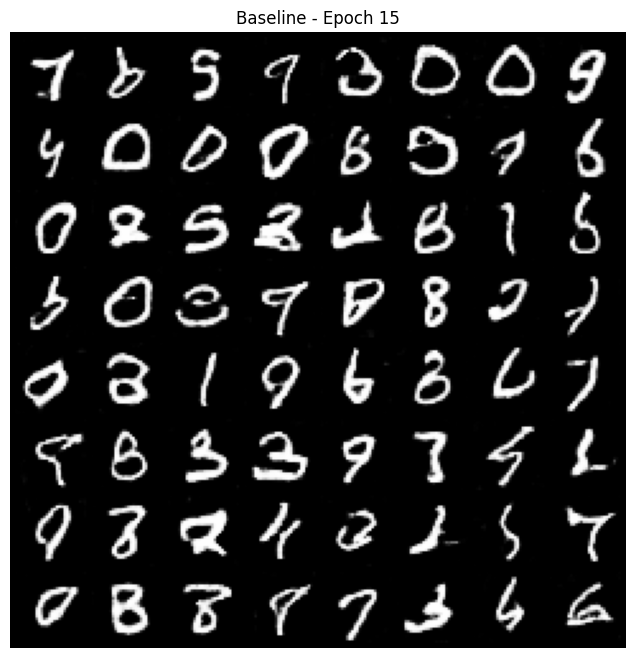

Epoch [16/20] | D Loss: 0.6379 | G Loss: 1.9865
Epoch [17/20] | D Loss: 0.6337 | G Loss: 2.0193
Epoch [18/20] | D Loss: 0.6344 | G Loss: 2.0386
Epoch [19/20] | D Loss: 0.6242 | G Loss: 2.0540
Epoch [20/20] | D Loss: 0.6134 | G Loss: 2.0834


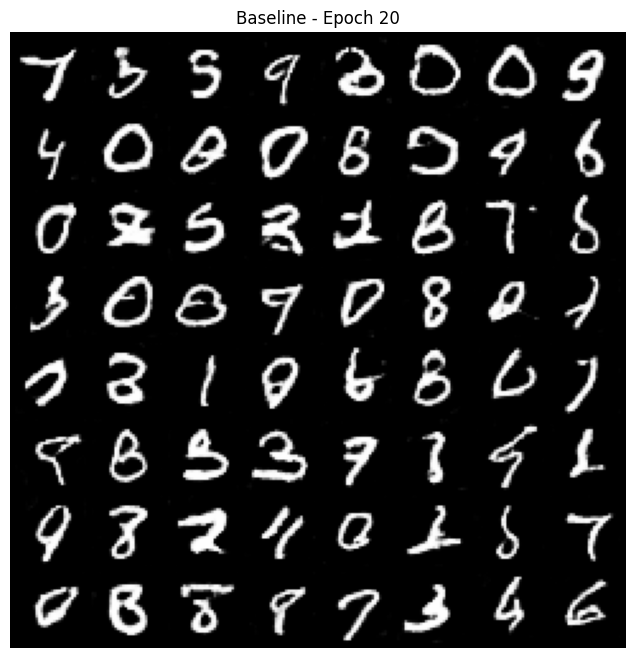

TRAINING COMPLETE: Baseline


In [ ]:
# ============================================================
# BASELINE EXPERIMENT
# ============================================================

baseline_results = train_dcgan(
    generator=G_baseline,
    discriminator=D_baseline,

    dataloader=dataloader,

    optimizer_G=optimizer_G_baseline,
    optimizer_D=optimizer_D_baseline,

    epochs=NUM_EPOCHS,

    fixed_noise=fixed_noise,

    result_folder="results/baseline",

    experiment_name="Baseline",

    label_smoothing=False
)

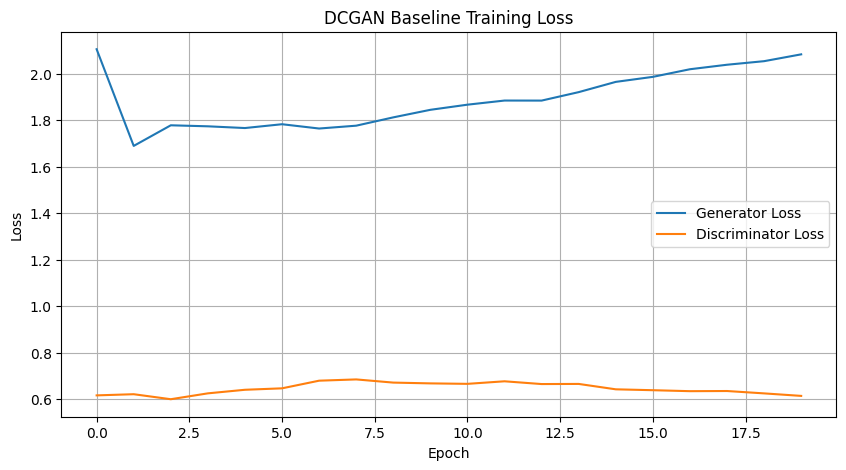

In [ ]:
# ============================================================
# BASELINE LOSS CURVES
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    baseline_results["epoch_g_losses"],
    label="Generator Loss"
)

plt.plot(
    baseline_results["epoch_d_losses"],
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "DCGAN Baseline Training Loss"
)

plt.legend()

plt.grid(True)

plt.savefig(
    "results/baseline/loss_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

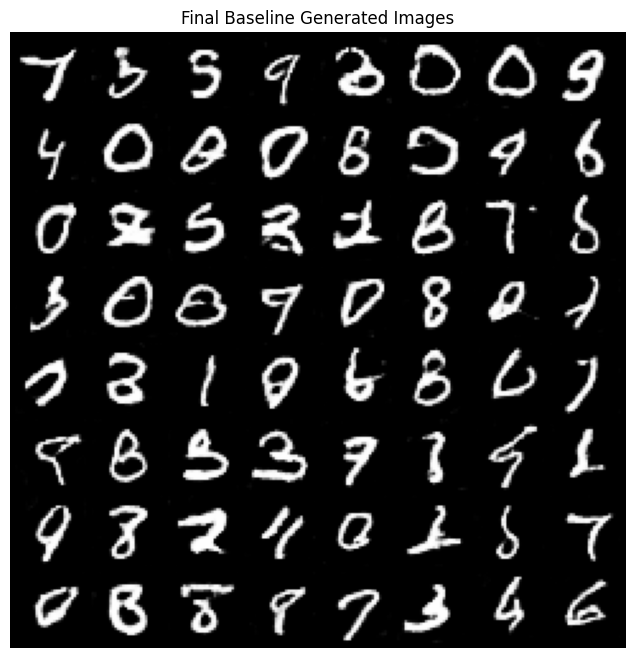

In [ ]:
# ============================================================
# FINAL BASELINE GENERATED IMAGES
# ============================================================

G_baseline.eval()

with torch.no_grad():

    baseline_final_images = G_baseline(
        fixed_noise
    )

G_baseline.train()


plt.figure(figsize=(8, 8))

grid = make_grid(
    baseline_final_images.cpu(),
    nrow=8,
    normalize=True
)

plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray"
)

plt.axis("off")

plt.title(
    "Final Baseline Generated Images"
)

plt.show()

In [ ]:
# ============================================================
# SAVE BASELINE MODELS
# ============================================================

torch.save(
    G_baseline.state_dict(),
    "models/generator_baseline.pth"
)

torch.save(
    D_baseline.state_dict(),
    "models/discriminator_baseline.pth"
)

print("Baseline models saved.")

Baseline models saved.


In [ ]:
# ============================================================
# LABEL SMOOTHING EXPERIMENT
# ============================================================

G_smooth = Generator(
    LATENT_DIM
).to(device)

D_smooth = Discriminator().to(device)


optimizer_G_smooth = optim.Adam(
    G_smooth.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D_smooth = optim.Adam(
    D_smooth.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

print("Label smoothing experiment initialized.")

Label smoothing experiment initialized.


STARTING: Label Smoothing
Epoch [01/20] | D Loss: 0.3467 | G Loss: 6.2844


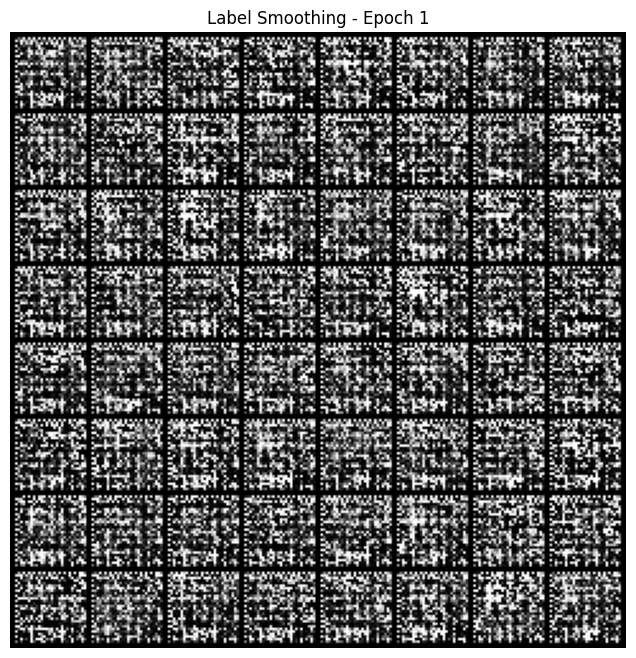

Epoch [02/20] | D Loss: 0.8449 | G Loss: 2.2675
Epoch [03/20] | D Loss: 0.7826 | G Loss: 1.7576
Epoch [04/20] | D Loss: 0.7337 | G Loss: 1.8925
Epoch [05/20] | D Loss: 0.7609 | G Loss: 1.8828


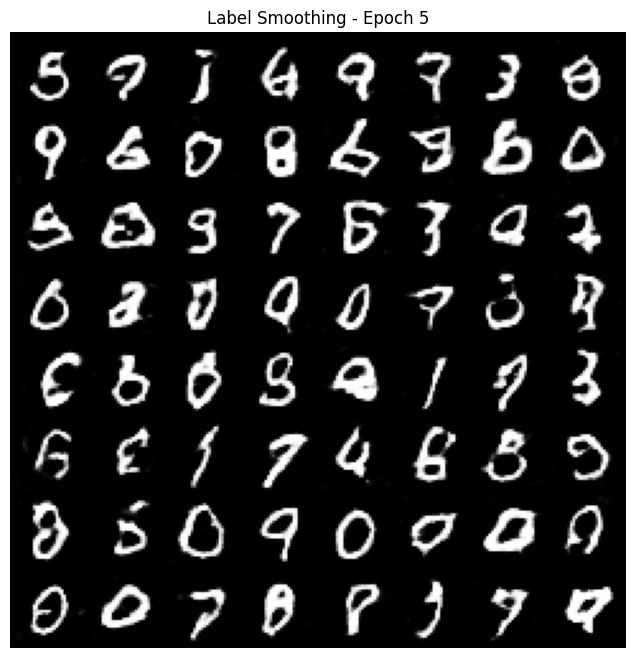

Epoch [06/20] | D Loss: 0.7743 | G Loss: 1.8785
Epoch [07/20] | D Loss: 0.8034 | G Loss: 1.8651
Epoch [08/20] | D Loss: 0.7999 | G Loss: 1.8627
Epoch [09/20] | D Loss: 0.7999 | G Loss: 1.8866
Epoch [10/20] | D Loss: 0.8008 | G Loss: 1.9052


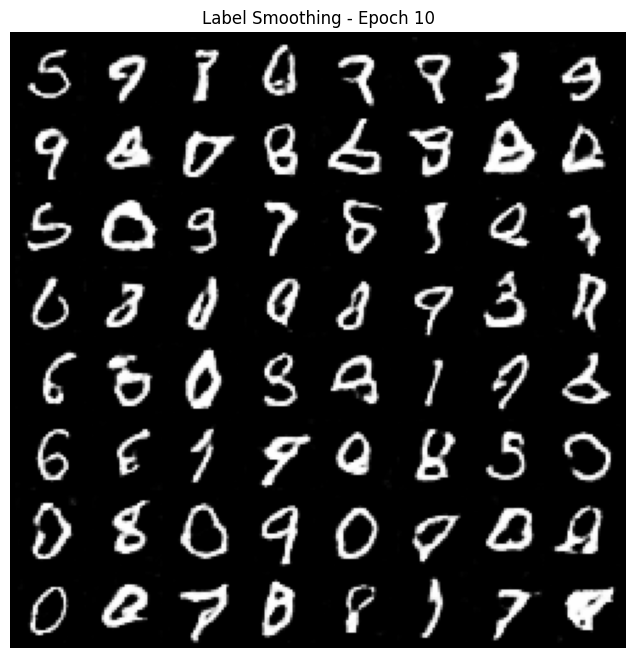

Epoch [11/20] | D Loss: 0.7970 | G Loss: 1.9357
Epoch [12/20] | D Loss: 0.8005 | G Loss: 1.9453
Epoch [13/20] | D Loss: 0.7952 | G Loss: 1.9678
Epoch [14/20] | D Loss: 0.7834 | G Loss: 2.0046
Epoch [15/20] | D Loss: 0.7802 | G Loss: 2.0258


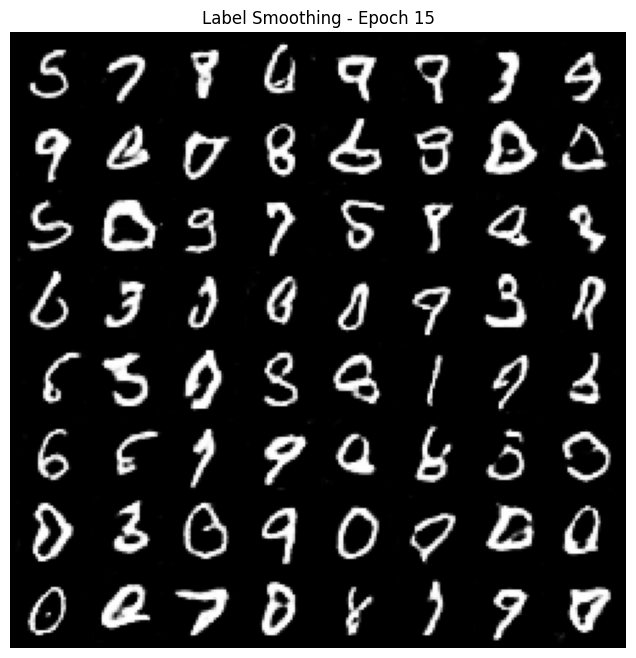

Epoch [16/20] | D Loss: 0.7827 | G Loss: 2.0389
Epoch [17/20] | D Loss: 0.7865 | G Loss: 2.0459
Epoch [18/20] | D Loss: 0.7741 | G Loss: 2.0732
Epoch [19/20] | D Loss: 0.7738 | G Loss: 2.0838
Epoch [20/20] | D Loss: 0.7657 | G Loss: 2.1044


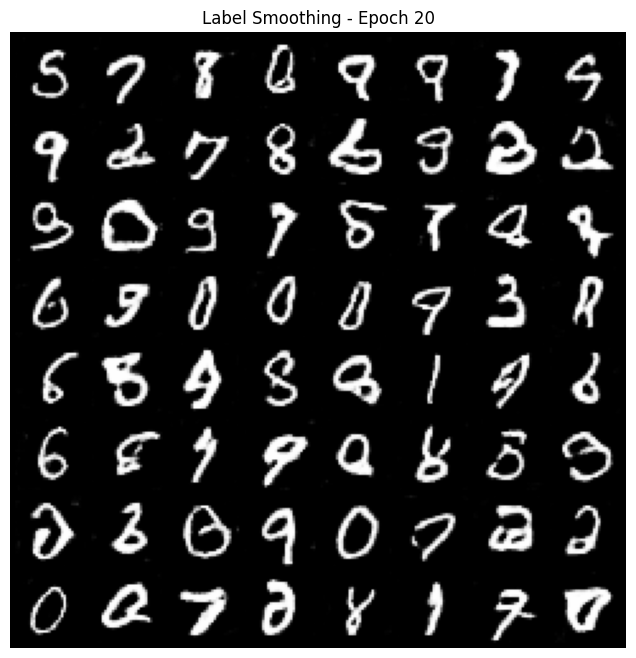

TRAINING COMPLETE: Label Smoothing


In [ ]:
# ============================================================
# TRAIN WITH LABEL SMOOTHING
# ============================================================

smooth_results = train_dcgan(
    generator=G_smooth,
    discriminator=D_smooth,

    dataloader=dataloader,

    optimizer_G=optimizer_G_smooth,
    optimizer_D=optimizer_D_smooth,

    epochs=NUM_EPOCHS,

    fixed_noise=fixed_noise,

    result_folder="results/label_smoothing",

    experiment_name="Label Smoothing",

    label_smoothing=True
)

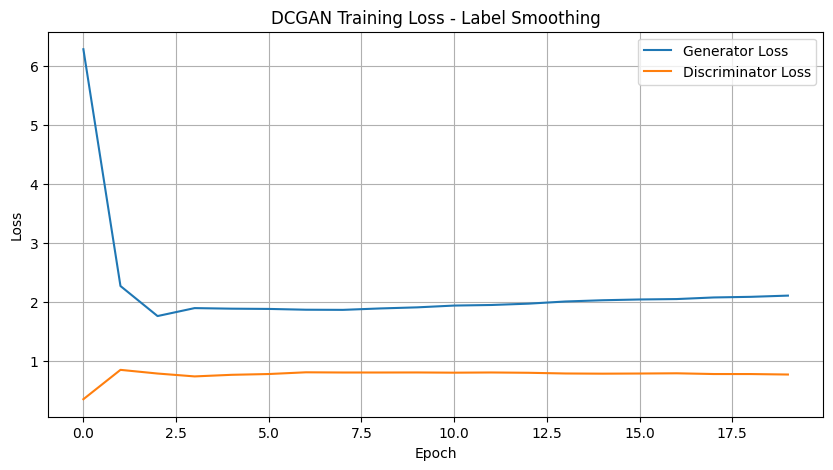

In [ ]:
# ============================================================
# LABEL SMOOTHING LOSS CURVE
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    smooth_results["epoch_g_losses"],
    label="Generator Loss"
)

plt.plot(
    smooth_results["epoch_d_losses"],
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "DCGAN Training Loss - Label Smoothing"
)

plt.legend()

plt.grid(True)

plt.savefig(
    "results/label_smoothing/loss_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

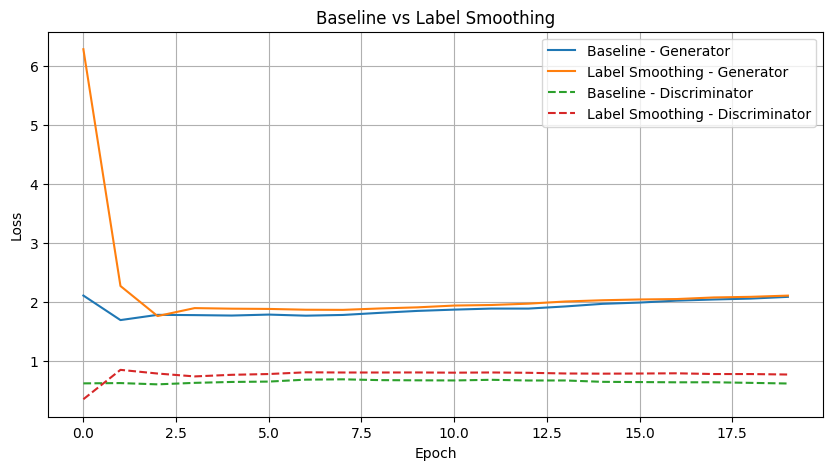

In [ ]:
# ============================================================
# BASELINE VS LABEL SMOOTHING
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    baseline_results["epoch_g_losses"],
    label="Baseline - Generator"
)

plt.plot(
    smooth_results["epoch_g_losses"],
    label="Label Smoothing - Generator"
)

plt.plot(
    baseline_results["epoch_d_losses"],
    linestyle="--",
    label="Baseline - Discriminator"
)

plt.plot(
    smooth_results["epoch_d_losses"],
    linestyle="--",
    label="Label Smoothing - Discriminator"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Baseline vs Label Smoothing"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# SAVE LABEL-SMOOTHED MODEL
# ============================================================

torch.save(
    G_smooth.state_dict(),
    "models/generator_label_smoothing.pth"
)

torch.save(
    D_smooth.state_dict(),
    "models/discriminator_label_smoothing.pth"
)

print("Label smoothing models saved.")

Label smoothing models saved.


In [ ]:
# ============================================================
# LEARNING RATE EXPERIMENT: 0.0001
# ============================================================

G_lr1 = Generator(
    LATENT_DIM
).to(device)

D_lr1 = Discriminator().to(device)


optimizer_G_lr1 = optim.Adam(
    G_lr1.parameters(),
    lr=0.0001,
    betas=(0.5, 0.999)
)

optimizer_D_lr1 = optim.Adam(
    D_lr1.parameters(),
    lr=0.0001,
    betas=(0.5, 0.999)
)

print("LR 0.0001 experiment initialized.")

LR 0.0001 experiment initialized.


STARTING: Learning Rate 0.0001
Epoch [01/20] | D Loss: 0.6343 | G Loss: 1.4776


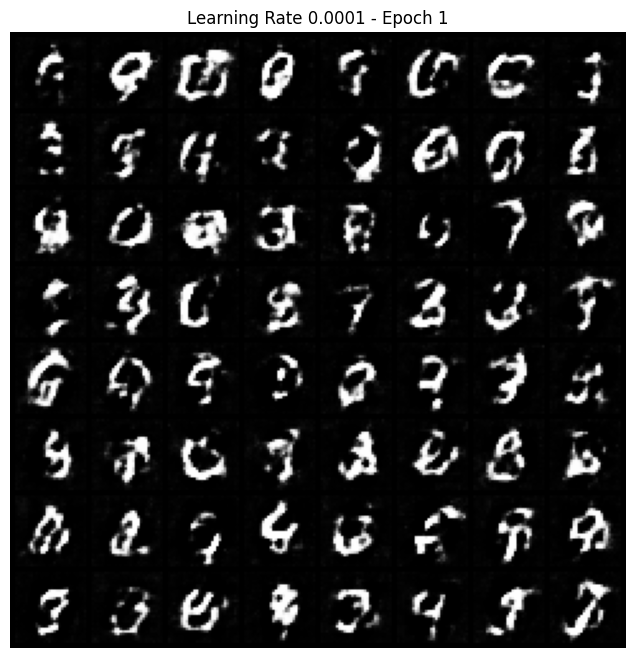

Epoch [02/20] | D Loss: 0.4836 | G Loss: 1.7999
Epoch [03/20] | D Loss: 0.5042 | G Loss: 1.8394
Epoch [04/20] | D Loss: 0.5149 | G Loss: 1.8533
Epoch [05/20] | D Loss: 0.5317 | G Loss: 1.8557


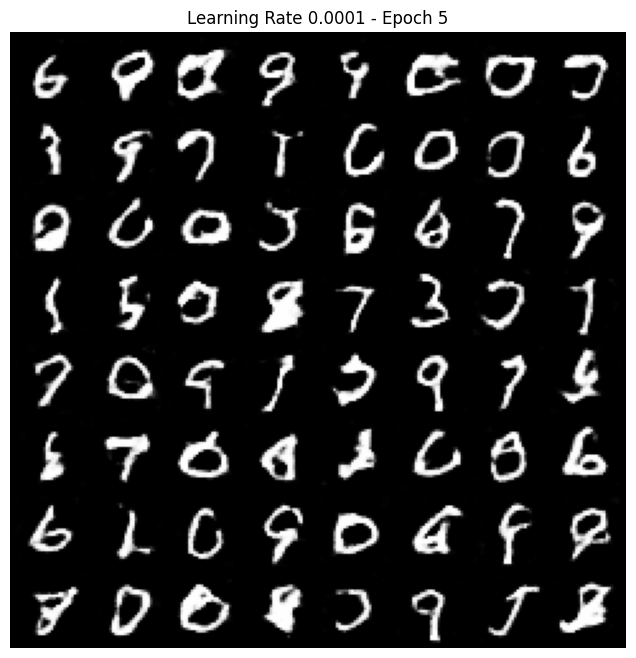

Epoch [06/20] | D Loss: 0.5460 | G Loss: 1.8458
Epoch [07/20] | D Loss: 0.5638 | G Loss: 1.8324
Epoch [08/20] | D Loss: 0.5747 | G Loss: 1.8226
Epoch [09/20] | D Loss: 0.5875 | G Loss: 1.8198
Epoch [10/20] | D Loss: 0.5959 | G Loss: 1.8242


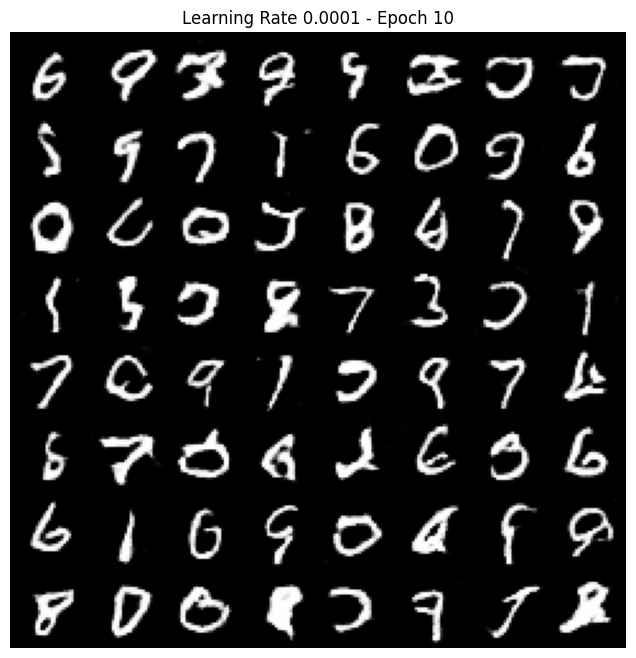

Epoch [11/20] | D Loss: 0.5973 | G Loss: 1.8317
Epoch [12/20] | D Loss: 0.5898 | G Loss: 1.8470
Epoch [13/20] | D Loss: 0.6048 | G Loss: 1.8538
Epoch [14/20] | D Loss: 0.6003 | G Loss: 1.8629
Epoch [15/20] | D Loss: 0.6018 | G Loss: 1.8700


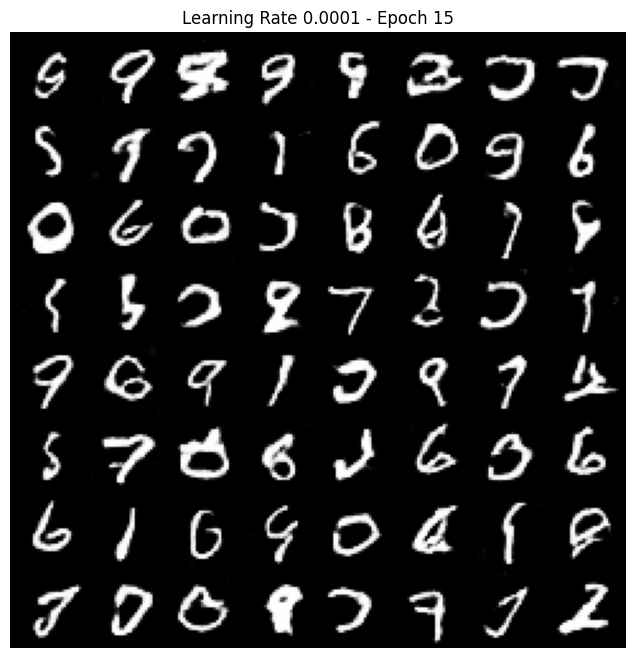

Epoch [16/20] | D Loss: 0.6101 | G Loss: 1.8713
Epoch [17/20] | D Loss: 0.6064 | G Loss: 1.8870
Epoch [18/20] | D Loss: 0.6011 | G Loss: 1.8971
Epoch [19/20] | D Loss: 0.6059 | G Loss: 1.9028
Epoch [20/20] | D Loss: 0.6029 | G Loss: 1.9179


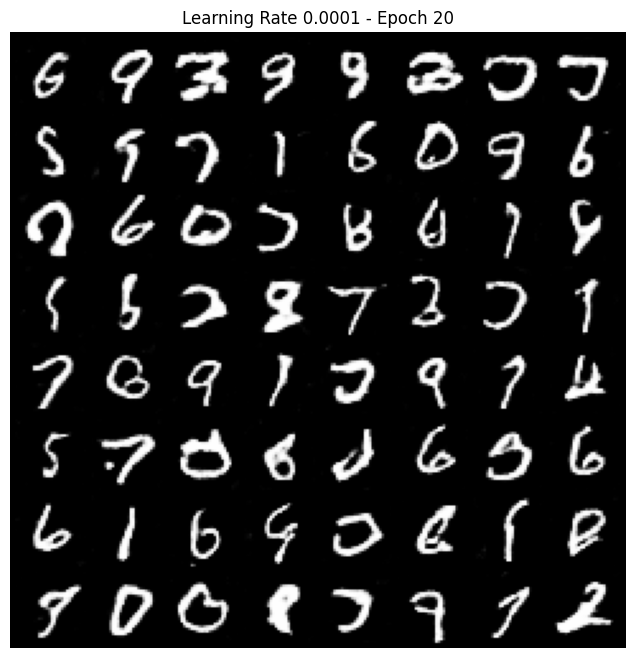

TRAINING COMPLETE: Learning Rate 0.0001


In [ ]:
# ============================================================
# TRAIN LR 0.0001
# ============================================================

lr1_results = train_dcgan(
    generator=G_lr1,
    discriminator=D_lr1,

    dataloader=dataloader,

    optimizer_G=optimizer_G_lr1,
    optimizer_D=optimizer_D_lr1,

    epochs=NUM_EPOCHS,

    fixed_noise=fixed_noise,

    result_folder="results/lr_0001",

    experiment_name="Learning Rate 0.0001",

    label_smoothing=False
)

In [ ]:
# ============================================================
# LEARNING RATE EXPERIMENT: 0.0003
# ============================================================

G_lr3 = Generator(
    LATENT_DIM
).to(device)

D_lr3 = Discriminator().to(device)


optimizer_G_lr3 = optim.Adam(
    G_lr3.parameters(),
    lr=0.0003,
    betas=(0.5, 0.999)
)

optimizer_D_lr3 = optim.Adam(
    D_lr3.parameters(),
    lr=0.0003,
    betas=(0.5, 0.999)
)

print("LR 0.0003 experiment initialized.")

LR 0.0003 experiment initialized.


STARTING: Learning Rate 0.0003
Epoch [01/20] | D Loss: 0.7957 | G Loss: 1.4787


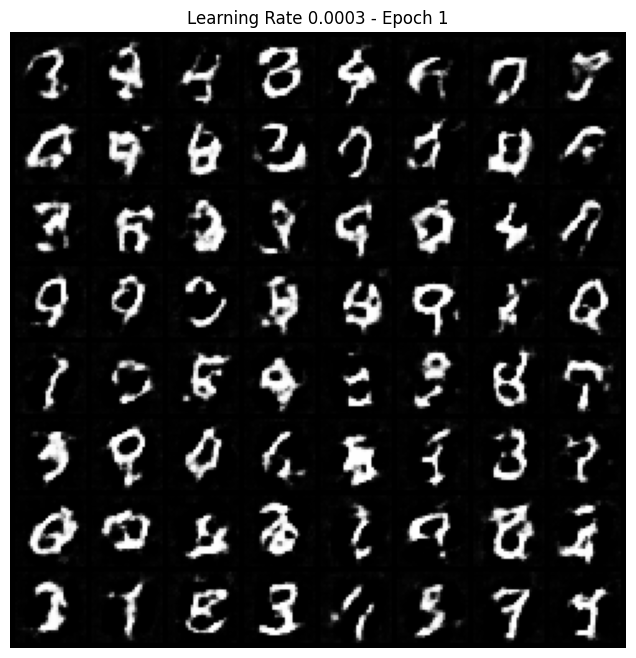

Epoch [02/20] | D Loss: 0.6969 | G Loss: 1.6725
Epoch [03/20] | D Loss: 0.7293 | G Loss: 1.6472
Epoch [04/20] | D Loss: 0.7330 | G Loss: 1.6820
Epoch [05/20] | D Loss: 0.7434 | G Loss: 1.6842


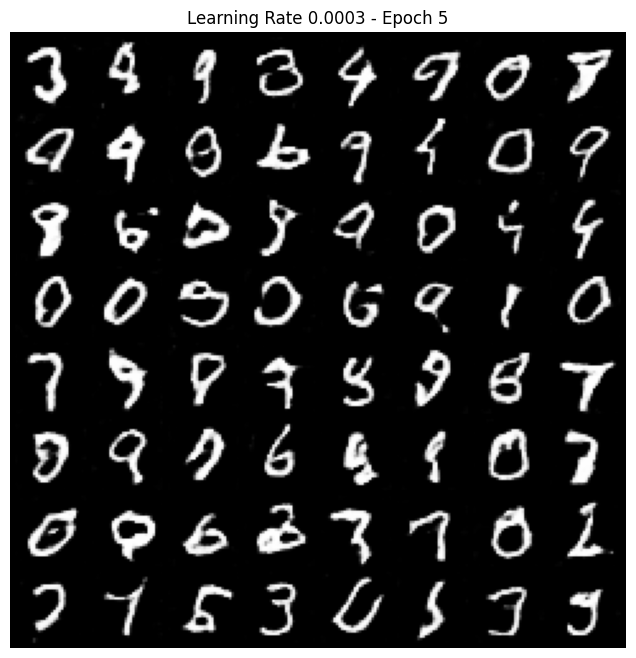

Epoch [06/20] | D Loss: 0.7194 | G Loss: 1.7544
Epoch [07/20] | D Loss: 0.7613 | G Loss: 1.7303
Epoch [08/20] | D Loss: 0.7152 | G Loss: 1.8142
Epoch [09/20] | D Loss: 0.7163 | G Loss: 1.8479
Epoch [10/20] | D Loss: 0.7141 | G Loss: 1.8648


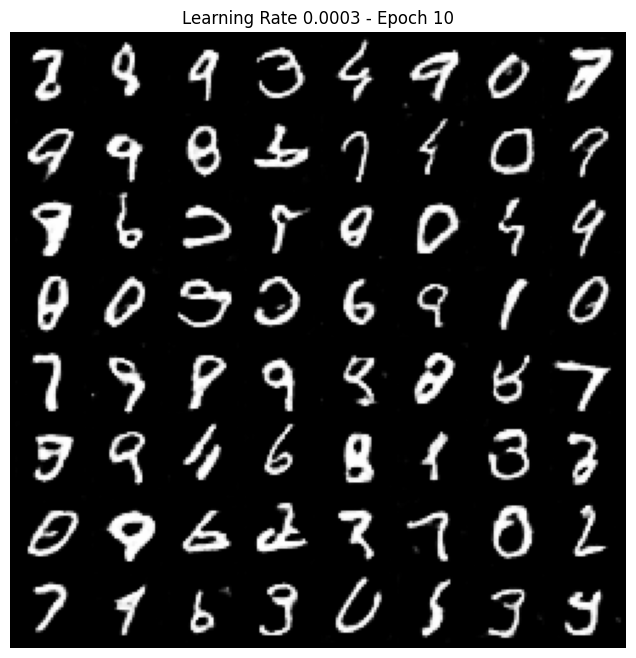

Epoch [11/20] | D Loss: 0.7173 | G Loss: 1.8958
Epoch [12/20] | D Loss: 0.6980 | G Loss: 1.9204
Epoch [13/20] | D Loss: 0.7019 | G Loss: 1.9488
Epoch [14/20] | D Loss: 0.6703 | G Loss: 2.0047
Epoch [15/20] | D Loss: 0.6691 | G Loss: 2.0216


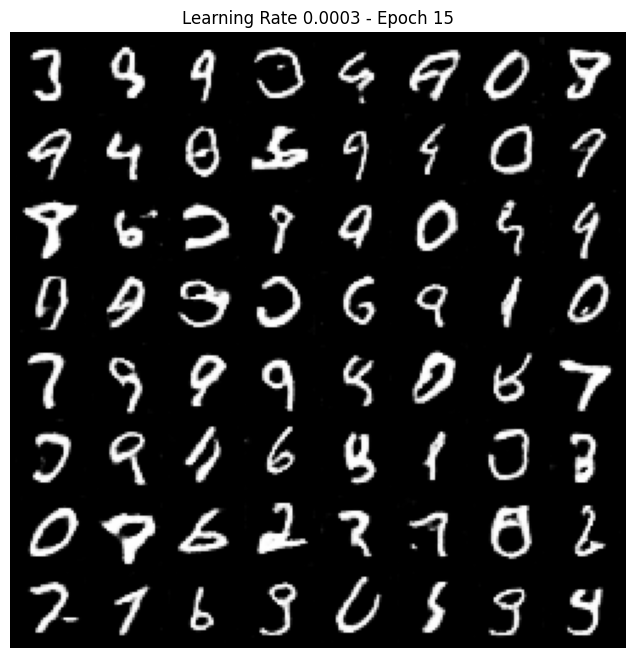

Epoch [16/20] | D Loss: 0.6913 | G Loss: 1.9936
Epoch [17/20] | D Loss: 0.6504 | G Loss: 2.0834
Epoch [18/20] | D Loss: 0.6411 | G Loss: 2.1218
Epoch [19/20] | D Loss: 0.6875 | G Loss: 2.0825
Epoch [20/20] | D Loss: 0.6419 | G Loss: 2.1125


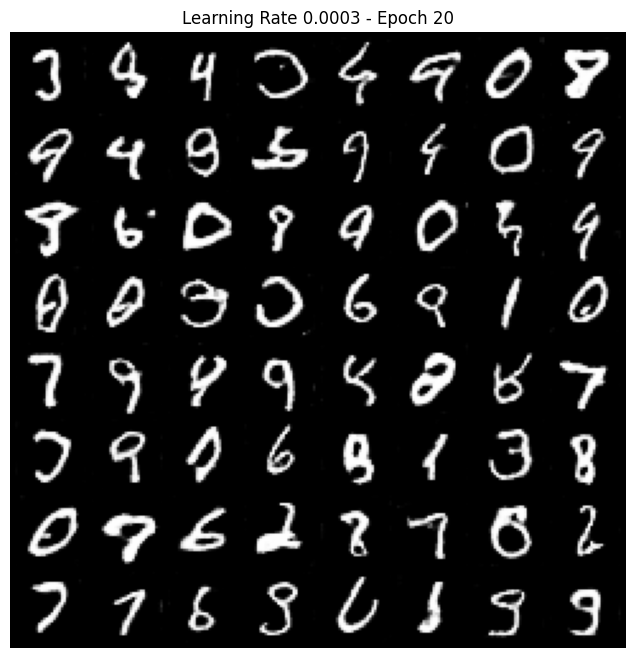

TRAINING COMPLETE: Learning Rate 0.0003


In [ ]:
# ============================================================
# TRAIN LR 0.0003
# ============================================================

lr3_results = train_dcgan(
    generator=G_lr3,
    discriminator=D_lr3,

    dataloader=dataloader,

    optimizer_G=optimizer_G_lr3,
    optimizer_D=optimizer_D_lr3,

    epochs=NUM_EPOCHS,

    fixed_noise=fixed_noise,

    result_folder="results/lr_0003",

    experiment_name="Learning Rate 0.0003",

    label_smoothing=False
)

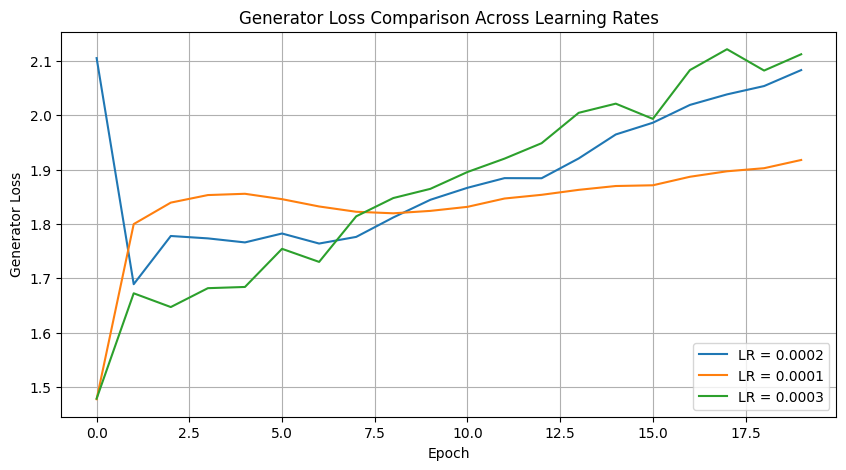

In [ ]:
# ============================================================
# LEARNING RATE COMPARISON
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    baseline_results["epoch_g_losses"],
    label="LR = 0.0002"
)

plt.plot(
    lr1_results["epoch_g_losses"],
    label="LR = 0.0001"
)

plt.plot(
    lr3_results["epoch_g_losses"],
    label="LR = 0.0003"
)

plt.xlabel("Epoch")
plt.ylabel("Generator Loss")

plt.title(
    "Generator Loss Comparison Across Learning Rates"
)

plt.legend()

plt.grid(True)

plt.show()

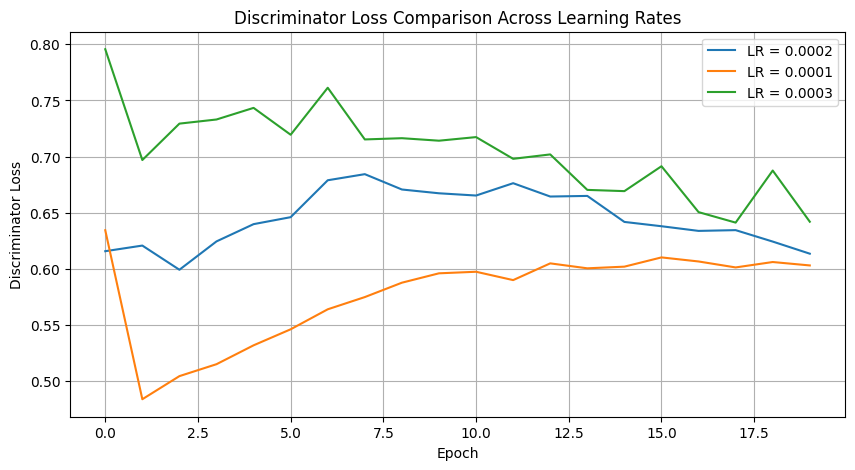

In [ ]:
# ============================================================
# DISCRIMINATOR LOSS COMPARISON
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    baseline_results["epoch_d_losses"],
    label="LR = 0.0002"
)

plt.plot(
    lr1_results["epoch_d_losses"],
    label="LR = 0.0001"
)

plt.plot(
    lr3_results["epoch_d_losses"],
    label="LR = 0.0003"
)

plt.xlabel("Epoch")
plt.ylabel("Discriminator Loss")

plt.title(
    "Discriminator Loss Comparison Across Learning Rates"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# GENERATE 1000 IMAGES
# ============================================================

G_baseline.eval()

NUM_GENERATED = 1000

diagnostic_noise = torch.randn(
    NUM_GENERATED,
    LATENT_DIM,
    1,
    1,
    device=device
)

with torch.no_grad():

    generated_samples = G_baseline(
        diagnostic_noise
    )

G_baseline.train()


print(
    "Generated sample shape:",
    generated_samples.shape
)

Generated sample shape: torch.Size([1000, 1, 28, 28])


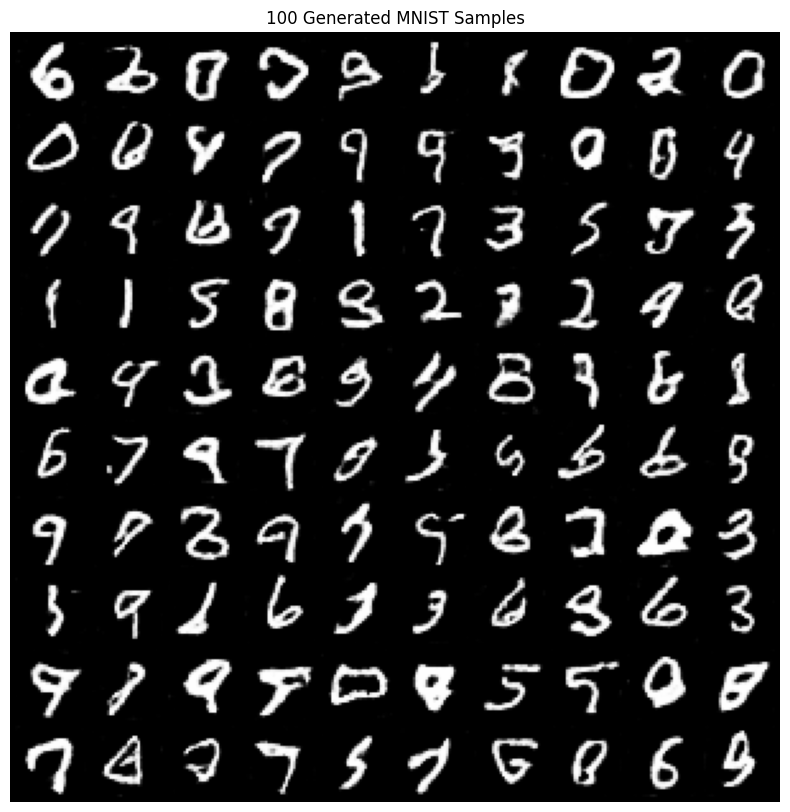

In [ ]:
# ============================================================
# VISUAL DIVERSITY CHECK
# ============================================================

plt.figure(figsize=(10, 10))

grid = make_grid(
    generated_samples[:100].cpu(),
    nrow=10,
    normalize=True
)

plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray"
)

plt.axis("off")

plt.title(
    "100 Generated MNIST Samples"
)

plt.show()

In [ ]:
# ============================================================
# SIMPLE PIXEL-BASED DIVERSITY DIAGNOSTIC
# ============================================================

samples = generated_samples[:200].detach().cpu()

# Flatten images
samples_flat = samples.view(
    samples.size(0),
    -1
)

# Calculate standard deviation across generated images
pixel_std = samples_flat.std(
    dim=0
)

mean_pixel_std = pixel_std.mean().item()

print(
    "Mean pixel standard deviation:",
    mean_pixel_std
)

Mean pixel standard deviation: 0.3831058144569397


In [ ]:
# ============================================================
# DIVERSITY COMPARISON FUNCTION
# ============================================================

def calculate_pixel_diversity(generator, num_samples=500):

    generator.eval()

    noise = torch.randn(
        num_samples,
        LATENT_DIM,
        1,
        1,
        device=device
    )

    with torch.no_grad():

        samples = generator(noise)

    generator.train()

    samples = samples.cpu()

    samples_flat = samples.view(
        num_samples,
        -1
    )

    diversity = samples_flat.std(
        dim=0
    ).mean().item()

    return diversity

In [ ]:
baseline_diversity = calculate_pixel_diversity(
    G_baseline
)

smooth_diversity = calculate_pixel_diversity(
    G_smooth
)

lr1_diversity = calculate_pixel_diversity(
    G_lr1
)

lr3_diversity = calculate_pixel_diversity(
    G_lr3
)

print("Baseline diversity:", baseline_diversity)
print("Label smoothing diversity:", smooth_diversity)
print("LR 0.0001 diversity:", lr1_diversity)
print("LR 0.0003 diversity:", lr3_diversity)

Baseline diversity: 0.3746403157711029
Label smoothing diversity: 0.3864578604698181
LR 0.0001 diversity: 0.38286933302879333
LR 0.0003 diversity: 0.3712155520915985


In [ ]:
# ============================================================
# FINAL EXPERIMENT SUMMARY
# ============================================================

experiment_summary = {
    "Baseline (LR 0.0002)": {
        "Learning Rate": 0.0002,
        "Label Smoothing": "No",
        "Diversity Score": baseline_diversity
    },

    "Label Smoothing": {
        "Learning Rate": 0.0002,
        "Label Smoothing": "Yes (0.9)",
        "Diversity Score": smooth_diversity
    },

    "Low LR": {
        "Learning Rate": 0.0001,
        "Label Smoothing": "No",
        "Diversity Score": lr1_diversity
    },

    "High LR": {
        "Learning Rate": 0.0003,
        "Label Smoothing": "No",
        "Diversity Score": lr3_diversity
    }
}

for name, result in experiment_summary.items():

    print("\n", name)
    print("-" * 40)

    for key, value in result.items():

        print(
            f"{key}: {value}"
        )


 Baseline (LR 0.0002)
----------------------------------------
Learning Rate: 0.0002
Label Smoothing: No
Diversity Score: 0.3746403157711029

 Label Smoothing
----------------------------------------
Learning Rate: 0.0002
Label Smoothing: Yes (0.9)
Diversity Score: 0.3864578604698181

 Low LR
----------------------------------------
Learning Rate: 0.0001
Label Smoothing: No
Diversity Score: 0.38286933302879333

 High LR
----------------------------------------
Learning Rate: 0.0003
Label Smoothing: No
Diversity Score: 0.3712155520915985


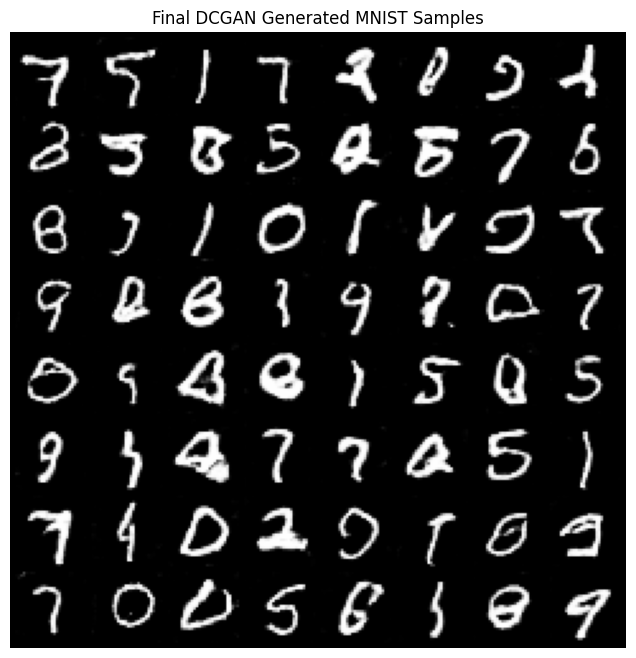

In [ ]:
# ============================================================
# FINAL MODEL SAMPLE GRID
# ============================================================

FINAL_GENERATOR = G_smooth

FINAL_GENERATOR.eval()

with torch.no_grad():

    final_noise = torch.randn(
        64,
        LATENT_DIM,
        1,
        1,
        device=device
    )

    final_images = FINAL_GENERATOR(
        final_noise
    )

FINAL_GENERATOR.train()


plt.figure(figsize=(8, 8))

grid = make_grid(
    final_images.cpu(),
    nrow=8,
    normalize=True
)

plt.imshow(
    grid.permute(1, 2, 0),
    cmap="gray"
)

plt.axis("off")

plt.title(
    "Final DCGAN Generated MNIST Samples"
)

plt.savefig(
    "results/final_generated_samples.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# SAVE FINAL GENERATOR
# ============================================================

torch.save(
    FINAL_GENERATOR.state_dict(),
    "models/generator_final.pth"
)

print(
    "Final Generator saved to:"
)

print(
    "models/generator_final.pth"
)

Final Generator saved to:
models/generator_final.pth


In [ ]:
# ============================================================
# SAVE EXPERIMENT RESULTS
# ============================================================

import json

results_to_save = {
    "baseline": {
        "learning_rate": 0.0002,
        "label_smoothing": False,
        "epoch_generator_losses":
            baseline_results["epoch_g_losses"],
        "epoch_discriminator_losses":
            baseline_results["epoch_d_losses"],
        "diversity":
            baseline_diversity
    },

    "label_smoothing": {
        "learning_rate": 0.0002,
        "label_smoothing": True,
        "epoch_generator_losses":
            smooth_results["epoch_g_losses"],
        "epoch_discriminator_losses":
            smooth_results["epoch_d_losses"],
        "diversity":
            smooth_diversity
    },

    "learning_rate_0.0001": {
        "learning_rate": 0.0001,
        "label_smoothing": False,
        "epoch_generator_losses":
            lr1_results["epoch_g_losses"],
        "epoch_discriminator_losses":
            lr1_results["epoch_d_losses"],
        "diversity":
            lr1_diversity
    },

    "learning_rate_0.0003": {
        "learning_rate": 0.0003,
        "label_smoothing": False,
        "epoch_generator_losses":
            lr3_results["epoch_g_losses"],
        "epoch_discriminator_losses":
            lr3_results["epoch_d_losses"],
        "diversity":
            lr3_diversity
    }
}


with open(
    "results/experiment_results.json",
    "w"
) as f:

    json.dump(
        results_to_save,
        f,
        indent=4
    )


print(
    "Experiment results saved."
)

Experiment results saved.


In [ ]:
# ============================================================
# PROJECT FILES
# ============================================================

for root, dirs, files in os.walk("."):

    # Ignore unnecessary system directories
    if root.startswith("./.config"):
        continue

    level = root.replace(".", "").count(os.sep)

    indent = "    " * level

    print(
        indent +
        os.path.basename(root) +
        "/"
    )

    subindent = "    " * (level + 1)

    for file in files:

        print(
            subindent +
            file
        )

./
    data/
        MNIST/
            raw/
                t10k-images-idx3-ubyte.gz
                train-labels-idx1-ubyte.gz
                train-images-idx3-ubyte.gz
                t10k-images-idx3-ubyte
                train-images-idx3-ubyte
                t10k-labels-idx1-ubyte.gz
                train-labels-idx1-ubyte
                t10k-labels-idx1-ubyte
    models/
        generator_final.pth
        discriminator_label_smoothing.pth
        generator_baseline.pth
        generator_label_smoothing.pth
        discriminator_baseline.pth
    results/
        final_generated_samples.png
        experiment_results.json
        label_smoothing/
            epoch_020.png
            epoch_015.png
            loss_curve.png
            epoch_010.png
            epoch_001.png
            epoch_005.png
        baseline/
            epoch_020.png
            epoch_015.png
            epoch_000.png
            loss_curve.png
            epoch_010.png
            epoch_001.png
   

In [ ]:
# ============================================================
# FINAL PROJECT SUMMARY
# ============================================================

print("=" * 65)
print("DCGAN MNIST PROJECT COMPLETED")
print("=" * 65)

print("\nDataset:")
print("  MNIST")
print("  60,000 training images")
print("  Image size: 28 x 28")
print("  Channels: 1")

print("\nGenerator:")
print("  Input:  (batch, 100, 1, 1)")
print("  Output: (batch, 1, 28, 28)")

print("\nDiscriminator:")
print("  Input:  (batch, 1, 28, 28)")
print("  Output: (batch, 1)")

print("\nExperiments:")
print("  1. Baseline")
print("  2. Label smoothing")
print("  3. Learning rate = 0.0001")
print("  4. Learning rate = 0.0003")

print("\nDiagnostics:")
print("  - Generated image checkpoints")
print("  - Generator loss")
print("  - Discriminator loss")
print("  - Pixel-based diversity indicator")
print("  - Visual mode-collapse inspection")

print("\nSaved outputs:")
print("  - Generated image grids")
print("  - Loss curves")
print("  - Trained models")
print("  - Experiment results")

print("\n" + "=" * 65)

DCGAN MNIST PROJECT COMPLETED

Dataset:
  MNIST
  60,000 training images
  Image size: 28 x 28
  Channels: 1

Generator:
  Input:  (batch, 100, 1, 1)
  Output: (batch, 1, 28, 28)

Discriminator:
  Input:  (batch, 1, 28, 28)
  Output: (batch, 1)

Experiments:
  1. Baseline
  2. Label smoothing
  3. Learning rate = 0.0001
  4. Learning rate = 0.0003

Diagnostics:
  - Generated image checkpoints
  - Generator loss
  - Discriminator loss
  - Pixel-based diversity indicator
  - Visual mode-collapse inspection

Saved outputs:
  - Generated image grids
  - Loss curves
  - Trained models
  - Experiment results



Diagnosing Mode Collapse & Training Instability

Training Instability: Diagnosed by monitoring the Generator Loss and Discriminator Loss curves. If the Discriminator loss drops to near zero, it has become too strong and the Generator stops learning. We mitigated this in our experiments using one-sided label smoothing, which sets the target for real images to 0.9 instead of 1.0, artificially softening the Discriminator's confidence.

Mode Collapse: Diagnosed by visually inspecting the final 64-image sample grids generated from a fixed noise batch, alongside the pixel-based diversity indicator. Because our final generated images display a wide variety of distinct digits (0-9) rather than collapsing into a single repeating shape, we can confirm that mode collapse did not occur during these training runs.